<center><h1>Huang_Shane_HW7</h1></center>

Name: Shane Huang
<br>
Github Username: shae513351
<br>
USC ID: 5886395143

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import balanced_accuracy_score, calinski_harabasz_score
from sklearn.cluster import KMeans
from imblearn.over_sampling import SMOTE # install imblearn
from imblearn.pipeline import Pipeline as ImbPipeline

SEED = 42

### (a) Download the Anuran Calls (MFCCs) Data Set

In [2]:
df = pd.read_csv(Path("../data/Frogs_MFCCs.csv"))
labels = ["Family", "Genus", "Species"]
X = df.filter(regex=r"^MFCCs")
y = df[labels]

# Use the same random split for all supervised models.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, random_state=SEED
)

display(pd.DataFrame({
    "Samples": [len(X), len(X_train), len(X_test)],
    "Features": [X.shape[1]] * 3
}, index=["Full", "Train", "Test"]))

print("Missing values:", df.isna().sum().sum())
display(y.nunique().rename("Classes").to_frame().T)

,Samples,Features
Full,7195,22
Train,5036,22
Test,2159,22


Missing values: 0


,Family,Genus,Species
Classes,4,8,10


### (b) Train a classifier for each label

#### (i) Research

Exact match (subset accuracy) is the proportion of samples whose
Family, Genus, and Species predictions are all correct.

We evaluate Hamming metrics across the three categorical targets.
Average Hamming distance is the mean number of incorrect targets
per sample. Hamming loss is this distance divided by three, and
Hamming score is defined here as 1 − Hamming loss.

Exact match and Hamming score are maximized; Hamming distance
and Hamming loss are minimized.

References:
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.hamming_loss.html

#### (ii) Train a SVM for each of the labels

In [3]:
# Create a funtion for multi-label classification in 1(b)ii, iii and iv
def evaluate_multilabel(y_true, y_pred):
    """Evaluate predictions across the three categorical targets."""
    correct = np.asarray(y_true) == np.asarray(y_pred)
    return {
        "Exact Match": correct.all(axis=1).mean(),
        "Hamming Distance": (~correct).sum(axis=1).mean(),
        "Hamming Loss": 1 - correct.mean(),
        "Hamming Score": correct.mean()
    }

In [4]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
rbf_grid = {
    "estimator__C": np.logspace(-2, 3, 6),
    "estimator__gamma": np.logspace(-2, 2, 5)
}
rbf_models, rbf_rows = {}, []
rbf_pred = pd.DataFrame(index=y_test.index)

# Tune one OvA classifier per target using training data only.
for label in labels:
    search = GridSearchCV(
        OneVsRestClassifier(SVC(kernel="rbf")),
        rbf_grid, cv=cv, scoring="accuracy", n_jobs=-1
    )
    search.fit(X_train, y_train[label])
    rbf_models[label] = search
    rbf_pred[label] = search.predict(X_test)
    params = search.best_params_
    rbf_rows.append({
        "Target": label,
        "C": params["estimator__C"],
        "gamma": params["estimator__gamma"],
        "CV Accuracy": search.best_score_,
        "Test Accuracy": (rbf_pred[label] == y_test[label]).mean()
    })

rbf_summary = pd.DataFrame(rbf_rows).set_index("Target")
display(rbf_summary.round(4))

,C,gamma,CV Accuracy,Test Accuracy
Target,,,,
Family,1000.0,1.0,0.9917,0.9958
Genus,10.0,1.0,0.9911,0.9903
Species,10.0,1.0,0.9901,0.9907


In [5]:
model_scores = {
    "RBF SVM": evaluate_multilabel(y_test, rbf_pred)
}
display(pd.DataFrame(model_scores).T.round(4))

,Exact Match,Hamming Distance,Hamming Loss,Hamming Score
RBF SVM,0.9875,0.0232,0.0077,0.9923


#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [6]:
l1_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("svm", LinearSVC(
        penalty="l1", loss="squared_hinge", dual=False,
        max_iter=100000, random_state=SEED
    ))
])
l1_grid = {"svm__C": np.logspace(-3, 2, 6)}
l1_models, l1_rows = {}, []
l1_pred = pd.DataFrame(index=y_test.index)

# Fit scaling within each CV training fold to prevent leakage.
for label in labels:
    search = GridSearchCV(
        l1_pipe, l1_grid, cv=cv, scoring="accuracy", n_jobs=-1
    )
    search.fit(X_train, y_train[label])
    l1_models[label] = search
    l1_pred[label] = search.predict(X_test)
    l1_rows.append({
        "Target": label,
        "C": search.best_params_["svm__C"],
        "CV Accuracy": search.best_score_,
        "Test Accuracy": (l1_pred[label] == y_test[label]).mean()
    })

l1_summary = pd.DataFrame(l1_rows).set_index("Target")
display(l1_summary.round(4))

,C,CV Accuracy,Test Accuracy
Target,,,
Family,10.0,0.9412,0.9282
Genus,100.0,0.9516,0.9416
Species,10.0,0.9607,0.9592


In [7]:
model_scores["L1 SVM"] = evaluate_multilabel(y_test, l1_pred)
display(pd.DataFrame(model_scores).T.round(4))

,Exact Match,Hamming Distance,Hamming Loss,Hamming Score
RBF SVM,0.9875,0.0232,0.0077,0.9923
L1 SVM,0.9125,0.1709,0.0570,0.9430


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [8]:
smote_pipe = ImbPipeline([
    ("scale", StandardScaler()),
    ("smote", SMOTE(random_state=SEED)),
    ("svm", LinearSVC(
        penalty="l1", loss="squared_hinge", dual=False,
        max_iter=100000, random_state=SEED
    ))
])
smote_models, smote_rows = {}, []
smote_pred = pd.DataFrame(index=y_test.index)

# Apply scaling and SMOTE only within each CV training fold.
for label in labels:
    search = GridSearchCV(
        smote_pipe, l1_grid, cv=cv, scoring="accuracy", n_jobs=-1
    )
    search.fit(X_train, y_train[label])
    smote_models[label] = search
    smote_pred[label] = search.predict(X_test)
    smote_rows.append({
        "Target": label,
        "C": search.best_params_["svm__C"],
        "CV Accuracy": search.best_score_,
        "Test Accuracy": (smote_pred[label] == y_test[label]).mean()
    })

smote_summary = pd.DataFrame(smote_rows).set_index("Target")
display(smote_summary.round(4))

,C,CV Accuracy,Test Accuracy
Target,,,
Family,10.0,0.9232,0.9092
Genus,1.0,0.9128,0.9023
Species,10.0,0.9581,0.9579


In [9]:
model_scores["L1 SVM + SMOTE"] = evaluate_multilabel(y_test, smote_pred)
display(pd.DataFrame(model_scores).T.round(4))

# Compare mean recall across classes to assess imbalance handling.
predictions = {
    "RBF SVM": rbf_pred,
    "L1 SVM": l1_pred,
    "L1 SVM + SMOTE": smote_pred
}
balanced_summary = pd.DataFrame({
    name: [
        balanced_accuracy_score(y_test[label], pred[label])
        for label in labels
    ]
    for name, pred in predictions.items()
}, index=labels)
display(balanced_summary.round(4))

,Exact Match,Hamming Distance,Hamming Loss,Hamming Score
RBF SVM,0.9875,0.0232,0.0077,0.9923
L1 SVM,0.9125,0.1709,0.0570,0.9430
L1 SVM + SMOTE,0.8536,0.2307,0.0769,0.9231


,RBF SVM,L1 SVM,L1 SVM + SMOTE
Family,0.9798,0.6902,0.9131
Genus,0.9656,0.7690,0.9162
Species,0.9750,0.8948,0.9278


SMOTE was applied separately for each target within the CV
training folds, after standardization. The selected C values
were 10, 1, and 10 for Family, Genus, and Species, respectively.

Compared with the original L1 SVM, SMOTE reduced exact match
from 0.9125 to 0.8536 and increased Hamming loss from 0.0570
to 0.0769. However, balanced accuracy increased from 0.6902
to 0.9131 for Family, 0.7690 to 0.9162 for Genus, and 0.8948
to 0.9278 for Species. Thus, SMOTE improved average recall
across classes at the expense of overall predictive accuracy.

The RBF SVM achieved the best exact match, Hamming metrics,
and balanced accuracy for all three targets in this experiment.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

Selected k: 2
Maximum CH score: 3680.74


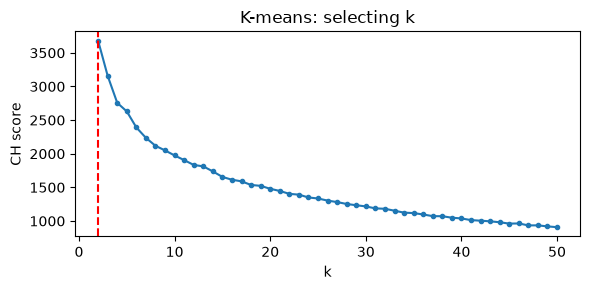

The case k = 1 was excluded because the index is undefined for a single cluster


In [10]:
def select_kmeans(X, seed):
    """Select k by maximizing CH; exclude k=1."""
    scores, best_model, best_score = [], None, -np.inf
    for k in range(2, 51):
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        score = calinski_harabasz_score(X, model.labels_)
        scores.append({"k": k, "CH": score})
        if score > best_score:
            best_model, best_score = model, score
    return best_model, pd.DataFrame(scores).set_index("k")

# First run; the same procedure will later be repeated 50 times.
kmeans, ch_scores = select_kmeans(X, SEED)
cluster_ids = kmeans.labels_

print(f"Selected k: {kmeans.n_clusters}")
print(f"Maximum CH score: {ch_scores['CH'].max():.2f}")

ax = ch_scores["CH"].plot(
    figsize=(6, 3), marker=".",
    xlabel="k", ylabel="CH score",
    title="K-means: selecting k"
)
ax.axvline(kmeans.n_clusters, color="red", linestyle="--")
plt.tight_layout()
plt.show()

print(f'The case k = 1 was excluded because the index is undefined for a single cluster')

### (b) Determine which family is the majority

In [11]:
def get_cluster_majorities(y, cluster_ids):
    """Find the most frequent value of each target within each cluster."""
    grouped = y.assign(Cluster=np.asarray(cluster_ids)).groupby("Cluster")
    
    # Break ties by taking the first value returned by mode().
    majorities = grouped[labels].agg(lambda col: col.mode().iloc[0])
    sizes = grouped.size().rename("Size")
    return majorities, sizes


cluster_majorities, cluster_sizes = get_cluster_majorities(y, cluster_ids)
display(cluster_majorities.join(cluster_sizes))

,Family,Genus,Species,Size
Cluster,,,,
0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus,3598
1,Hylidae,Hypsiboas,HypsiboasCordobae,3597


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [12]:
def evaluate_clusters(y, cluster_ids, majorities):
    """Assign cluster-majority labels and evaluate all observations."""
    predictions = majorities.loc[np.asarray(cluster_ids), labels].to_numpy()
    return evaluate_multilabel(y[labels], predictions)


cluster_scores = evaluate_clusters(y, cluster_ids, cluster_majorities)
display(pd.DataFrame([cluster_scores], index=["K-means"]).round(4))

,Exact Match,Hamming Distance,Hamming Loss,Hamming Score
K-means,0.6361,0.8956,0.2985,0.7015


In [13]:
experiment_rows = []

# Repeat clustering, k selection, and majority-label evaluation 50 times.
for run in range(50):
    seed = SEED + run
    model, _ = select_kmeans(X, seed)
    majorities, _ = get_cluster_majorities(y, model.labels_)
    scores = evaluate_clusters(y, model.labels_, majorities)

    experiment_rows.append({
        "Run": run + 1,
        "Selected k": model.n_clusters,
        **scores
    })

    # Show occasional progress without printing every result.
    # if (run + 1) % 10 == 0:
    #    print(f"Completed {run + 1}/50 runs")

experiment_results = pd.DataFrame(experiment_rows).set_index("Run")

metrics = ["Hamming Distance", "Hamming Loss", "Hamming Score"]
experiment_summary = (
    experiment_results[metrics]
    .agg(["mean", "std"])
    .T.rename(columns={"mean": "Mean", "std": "Std"})
)
display(experiment_summary.round(6))

# Summarize how often each k was selected.
display(
    experiment_results["Selected k"]
    .value_counts()
    .sort_index()
    .rename_axis("Selected k")
    .to_frame("Runs")
)

,Mean,Std
Hamming Distance,0.895622,0.0
Hamming Loss,0.298541,0.0
Hamming Score,0.701459,0.0


,Runs
Selected k,
2,50


## 3. ISLR 12.6.2

### (a)
Using complete linkage, observations 1 and 2 merge at height 0.30,
followed by observations 3 and 4 at height 0.45. The two clusters
then merge at height 0.80, the maximum pairwise dissimilarity
between {1, 2} and {3, 4}.

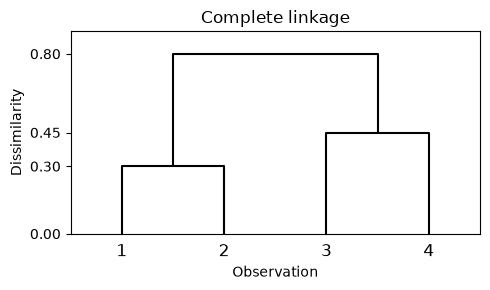

In [14]:
from scipy.cluster.hierarchy import dendrogram

# Record the manually derived complete-linkage merges.
Z_complete = np.array([
    [0, 1, 0.30, 2],
    [2, 3, 0.45, 2],
    [4, 5, 0.80, 4]
])

fig, ax = plt.subplots(figsize=(5, 3))
dendrogram(
    Z_complete, labels=["1", "2", "3", "4"],
    color_threshold=0, above_threshold_color="black", ax=ax
)
ax.set(
    xlabel="Observation", ylabel="Dissimilarity",
    title="Complete linkage", ylim=(0, 0.9)
)
ax.set_yticks([0, 0.30, 0.45, 0.80])
plt.tight_layout()
plt.show()

### (b)
Using single linkage clustering this time, observations 1 and 2 merge at height 0.30.
Observation 3 joins this cluster at height 0.40, and observation 4
joins at height 0.45. Each merge uses the minimum pairwise
dissimilarity between the two clusters.

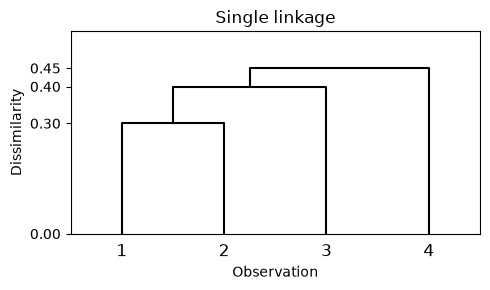

In [15]:
# Record the manually derived single-linkage merges.
Z_single = np.array([
    [0, 1, 0.30, 2],
    [4, 2, 0.40, 3],
    [5, 3, 0.45, 4]
])

fig, ax = plt.subplots(figsize=(5, 3))
dendrogram(
    Z_single, labels=["1", "2", "3", "4"],
    color_threshold=0, above_threshold_color="black", ax=ax
)
ax.set(
    xlabel="Observation", ylabel="Dissimilarity",
    title="Single linkage", ylim=(0, 0.55)
)
ax.set_yticks([0, 0.30, 0.40, 0.45])
plt.tight_layout()
plt.show()

### (c)
Cutting the complete-linkage dendrogram at any height
between 0.45 and 0.80 gives two clusters: {1, 2} and {3, 4}.

### (d)
Cutting the single-linkage dendrogram at any height
between 0.40 and 0.45 gives two clusters: {1, 2, 3} and {4}.

### (e)
Swapping leaves 1 and 2 gives the order 2, 1, 3, 4.
The dendrogram is equivalent to (a) because all cluster
memberships and merge heights remain unchanged.

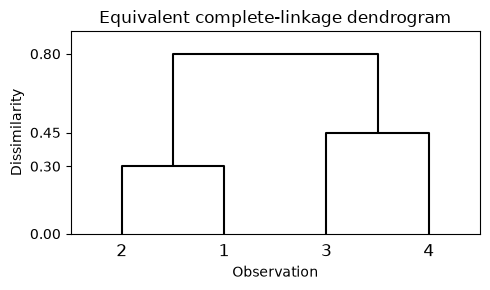

In [16]:
# Swap the children of the first merge to reverse leaves 1 and 2.
Z_equivalent = Z_complete.copy()
Z_equivalent[0, :2] = Z_equivalent[0, :2][::-1]

fig, ax = plt.subplots(figsize=(5, 3))
dendrogram(
    Z_equivalent, labels=["1", "2", "3", "4"],
    color_threshold=0, above_threshold_color="black", ax=ax
)
ax.set(
    xlabel="Observation", ylabel="Dissimilarity",
    title="Equivalent complete-linkage dendrogram", ylim=(0, 0.9)
)
ax.set_yticks([0, 0.30, 0.45, 0.80])
plt.tight_layout()
plt.show()